In [1]:
!pip install "numpy<2.0.0" "pandas<2.2.0" "scipy<1.13.0" "matplotlib<3.9.0" qiskit qiskit-aer quimb mqt.ddsim cirq qsimcirq pyqrack psutil pyqrack-cpu

In [31]:
%%writefile qmem_workers.py
"""
Worker functions for the quantum simulator memory benchmark.

This MUST be a real .py file on disk (not defined in a notebook cell).
multiprocessing's 'spawn' start method re-imports the module that defines
each worker function inside the fresh child interpreter — if the function
lives only in a notebook's __main__ namespace, there's nothing on disk to
re-import, which is exactly the
    AttributeError: Can't get attribute '_run_qiskit' on <module '__main__'>
error you hit.
"""

import traceback
import resource


def _peak_mem_mb():
    """Peak RSS of *this* process so far, in MB. Kernel-tracked, no polling."""
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024.0


def run_qiskit(n, q):
    try:
        from qiskit import QuantumCircuit
        from qiskit_aer import AerSimulator

        backend = AerSimulator(method='statevector')

        # Warm-up: trigger one-time backend init (thread pools, allocator
        # caches, etc.) BEFORE the baseline snapshot, so only the memory
        # that actually depends on N gets measured below.
        warm = QuantumCircuit(1)
        warm.h(0)
        warm.save_statevector()
        backend.run(warm).result()

        baseline = _peak_mem_mb()

        qc = QuantumCircuit(n)
        qc.h(range(n))
        qc.save_statevector()
        result = backend.run(qc).result()
        _ = result.get_statevector()

        q.put({'mem': max(0.0, _peak_mem_mb() - baseline), 'error': None})
    except Exception:
        q.put({'mem': None, 'error': traceback.format_exc()})


def run_qsim(n, q):
    try:
        import cirq
        import qsimcirq

        sim = qsimcirq.QSimSimulator()

        warm_qubits = cirq.LineQubit.range(1)
        sim.simulate(cirq.Circuit(cirq.H(warm_qubits[0])))

        baseline = _peak_mem_mb()

        qubits = cirq.LineQubit.range(n)
        circuit = cirq.Circuit(cirq.H(qb) for qb in qubits)
        _ = sim.simulate(circuit)

        q.put({'mem': max(0.0, _peak_mem_mb() - baseline), 'error': None})
    except Exception:
        q.put({'mem': None, 'error': traceback.format_exc()})


def run_quimb(n, q):
    try:
        import quimb.tensor as qtn

        warm = qtn.Circuit(1)
        warm.apply_gate('H', 0)
        _ = warm.psi.contract()  # Fixed: force contraction

        baseline = _peak_mem_mb()

        circ = qtn.Circuit(n)
        for i in range(n):
            circ.apply_gate('H', i)
        
        _ = circ.psi.contract()  # Fixed: force contraction

        q.put({'mem': max(0.0, _peak_mem_mb() - baseline), 'error': None})
    except Exception:
        q.put({'mem': None, 'error': traceback.format_exc()})


def run_ddsim(n, q):
    try:
        from qiskit import QuantumCircuit
        from mqt.ddsim import DDSIMProvider

        provider = DDSIMProvider()
        backend = provider.get_backend('qasm_simulator')

        # Warm-up: DDSIM builds its decision-diagram package (unique tables,
        # complex-number cache) on first use, which is a large fixed cost
        # unrelated to N. Trigger it here, before the baseline snapshot.
        warm = QuantumCircuit(1)
        warm.h(0)
        warm.measure_all()
        backend.run(warm, shots=1).result()

        baseline = _peak_mem_mb()

        qc = QuantumCircuit(n)
        qc.h(range(n))
        qc.measure_all()
        _ = backend.run(qc, shots=1).result()

        q.put({'mem': max(0.0, _peak_mem_mb() - baseline), 'error': None})
    except Exception:
        q.put({'mem': None, 'error': traceback.format_exc()})


def run_pyqrack(n, q):
    try:
        from pyqrack import QrackSimulator

        warm = QrackSimulator(1)
        warm.h(0)
        warm.m(0) # Fixed: force evaluation
        del warm

        baseline = _peak_mem_mb()

        sim = QrackSimulator(n)
        for i in range(n):
            sim.h(i)
            
        sim.m(0) # Fixed: force evaluation

        q.put({'mem': max(0.0, _peak_mem_mb() - baseline), 'error': None})
    except Exception:
        q.put({'mem': None, 'error': traceback.format_exc()})

Overwriting qmem_workers.py


In [15]:
%%writefile qmem_workers.py
"""
Worker functions for the quantum simulator memory benchmark.
Now featuring a linear chain of CNOT gates to force entanglement.
"""

import traceback
import resource


def _peak_mem_mb():
    """Peak RSS of *this* process so far, in MB. Kernel-tracked, no polling."""
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024.0


def run_qiskit(n, q):
    try:
        from qiskit import QuantumCircuit
        from qiskit_aer import AerSimulator

        backend = AerSimulator(method='statevector')

        # Warm-up
        warm = QuantumCircuit(2)
        warm.h(0)
        warm.cx(0, 1)
        warm.save_statevector()
        backend.run(warm).result()

        baseline = _peak_mem_mb()

        qc = QuantumCircuit(n)
        qc.h(range(n))
        # Add 1D chain of entanglement
        for i in range(n - 1):
            qc.cx(i, i + 1)
            
        qc.save_statevector()
        result = backend.run(qc).result()
        _ = result.get_statevector()

        q.put({'mem': max(0.0, _peak_mem_mb() - baseline), 'error': None})
    except Exception:
        q.put({'mem': None, 'error': traceback.format_exc()})


def run_qsim(n, q):
    try:
        import cirq
        import qsimcirq

        sim = qsimcirq.QSimSimulator()

        # Warm-up
        warm_qubits = cirq.LineQubit.range(2)
        warm_qc = cirq.Circuit(cirq.H(warm_qubits[0]), cirq.CX(warm_qubits[0], warm_qubits[1]))
        sim.simulate(warm_qc)

        baseline = _peak_mem_mb()

        qubits = cirq.LineQubit.range(n)
        circuit = cirq.Circuit()
        for qb in qubits:
            circuit.append(cirq.H(qb))
        # Add 1D chain of entanglement
        for i in range(n - 1):
            circuit.append(cirq.CX(qubits[i], qubits[i + 1]))
            
        _ = sim.simulate(circuit)

        q.put({'mem': max(0.0, _peak_mem_mb() - baseline), 'error': None})
    except Exception:
        q.put({'mem': None, 'error': traceback.format_exc()})


def run_quimb(n, q):
    try:
        import quimb.tensor as qtn

        # Warm-up
        warm = qtn.Circuit(2)
        warm.apply_gate('H', 0)
        warm.apply_gate('CX', 0, 1)
        _ = warm.psi

        baseline = _peak_mem_mb()

        circ = qtn.Circuit(n)
        for i in range(n):
            circ.apply_gate('H', i)
        # Add 1D chain of entanglement
        for i in range(n - 1):
            circ.apply_gate('CX', i, i + 1)
            
        _ = circ.psi

        q.put({'mem': max(0.0, _peak_mem_mb() - baseline), 'error': None})
    except Exception:
        q.put({'mem': None, 'error': traceback.format_exc()})


def run_ddsim(n, q):
    try:
        from qiskit import QuantumCircuit
        from mqt.ddsim import DDSIMProvider

        provider = DDSIMProvider()
        backend = provider.get_backend('qasm_simulator')

        # Warm-up
        warm = QuantumCircuit(2)
        warm.h(0)
        warm.cx(0, 1)
        warm.measure_all()
        backend.run(warm, shots=1).result()

        baseline = _peak_mem_mb()

        qc = QuantumCircuit(n)
        qc.h(range(n))
        # Add 1D chain of entanglement
        for i in range(n - 1):
            qc.cx(i, i + 1)
            
        qc.measure_all()
        _ = backend.run(qc, shots=1).result()

        q.put({'mem': max(0.0, _peak_mem_mb() - baseline), 'error': None})
    except Exception:
        q.put({'mem': None, 'error': traceback.format_exc()})


def run_pyqrack(n, q):
    try:
        from pyqrack import QrackSimulator

        # Warm-up
        warm = QrackSimulator(2)
        warm.h(0)
        warm.mcx([0], 1)
        del warm

        baseline = _peak_mem_mb()

        sim = QrackSimulator(n)
        for i in range(n):
            sim.h(i)
        # Add 1D chain of entanglement
        for i in range(n - 1):
            sim.mcx([i], i + 1)

        q.put({'mem': max(0.0, _peak_mem_mb() - baseline), 'error': None})
    except Exception:
        q.put({'mem': None, 'error': traceback.format_exc()})

Overwriting qmem_workers.py


In [19]:
%%writefile qmem_workers.py
"""
Worker functions for the quantum simulator memory benchmark.
Features multi-layer brickwork entanglement and non-Clifford phase rotations
to force high entanglement volume and break decision diagram symmetries.
"""

import traceback
import resource
import math


def _peak_mem_mb():
    """Peak RSS of *this* process so far, in MB. Kernel-tracked, no polling."""
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024.0


def run_qiskit(n, q):
    try:
        from qiskit import QuantumCircuit
        from qiskit_aer import AerSimulator

        backend = AerSimulator(method='statevector')

        # Warm-up
        warm = QuantumCircuit(2)
        warm.h(0)
        warm.rz(math.pi / 7, 0)
        warm.cx(0, 1)
        warm.save_statevector()
        backend.run(warm).result()

        baseline = _peak_mem_mb()

        qc = QuantumCircuit(n)
        # Layer 1: Superposition + Non-Clifford Rotations
        qc.h(range(n))
        for i in range(n):
            qc.rz(math.pi / (i + 3), i)

        # Layer 2: Even-odd CNOT brickwork
        for i in range(0, n - 1, 2):
            qc.cx(i, i + 1)

        # Layer 3: Odd-even CNOT brickwork
        for i in range(1, n - 1, 2):
            qc.cx(i, i + 1)

        # Layer 4: Additional rotations + wrapping CNOT
        for i in range(n):
            qc.ry(math.pi / (i + 2), i)
        if n > 1:
            qc.cx(0, n - 1)

        qc.save_statevector()
        result = backend.run(qc).result()
        _ = result.get_statevector()

        q.put({'mem': max(0.0, _peak_mem_mb() - baseline), 'error': None})
    except Exception:
        q.put({'mem': None, 'error': traceback.format_exc()})


def run_qsim(n, q):
    try:
        import cirq
        import qsimcirq

        sim = qsimcirq.QSimSimulator()

        # Warm-up
        warm_qubits = cirq.LineQubit.range(2)
        warm_qc = cirq.Circuit(
            cirq.H(warm_qubits[0]),
            cirq.rz(rads=math.pi / 7)(warm_qubits[0]),
            cirq.CX(warm_qubits[0], warm_qubits[1])
        )
        sim.simulate(warm_qc)

        baseline = _peak_mem_mb()

        qubits = cirq.LineQubit.range(n)
        circuit = cirq.Circuit()

        # Layer 1: Superposition + Non-Clifford Rotations
        for i, qb in enumerate(qubits):
            circuit.append(cirq.H(qb))
            circuit.append(cirq.rz(rads=math.pi / (i + 3))(qb))

        # Layer 2: Even-odd CNOT brickwork
        for i in range(0, n - 1, 2):
            circuit.append(cirq.CX(qubits[i], qubits[i + 1]))

        # Layer 3: Odd-even CNOT brickwork
        for i in range(1, n - 1, 2):
            circuit.append(cirq.CX(qubits[i], qubits[i + 1]))

        # Layer 4: Additional rotations + wrapping CNOT
        for i, qb in enumerate(qubits):
            circuit.append(cirq.ry(rads=math.pi / (i + 2))(qb))
        if n > 1:
            circuit.append(cirq.CX(qubits[0], qubits[n - 1]))

        _ = sim.simulate(circuit)

        q.put({'mem': max(0.0, _peak_mem_mb() - baseline), 'error': None})
    except Exception:
        q.put({'mem': None, 'error': traceback.format_exc()})


def run_quimb(n, q):
    try:
        import quimb.tensor as qtn

        # Warm-up
        warm = qtn.Circuit(2)
        warm.apply_gate('H', 0)
        warm.apply_gate('RZ', math.pi / 7, 0)
        warm.apply_gate('CX', 0, 1)
        _ = warm.psi

        baseline = _peak_mem_mb()

        circ = qtn.Circuit(n)

        # Layer 1: Superposition + Non-Clifford Rotations
        for i in range(n):
            circ.apply_gate('H', i)
            circ.apply_gate('RZ', math.pi / (i + 3), i)

        # Layer 2: Even-odd CNOT brickwork
        for i in range(0, n - 1, 2):
            circ.apply_gate('CX', i, i + 1)

        # Layer 3: Odd-even CNOT brickwork
        for i in range(1, n - 1, 2):
            circ.apply_gate('CX', i, i + 1)

        # Layer 4: Additional rotations + wrapping CNOT
        for i in range(n):
            circ.apply_gate('RY', math.pi / (i + 2), i)
        if n > 1:
            circ.apply_gate('CX', 0, n - 1)

        _ = circ.psi

        q.put({'mem': max(0.0, _peak_mem_mb() - baseline), 'error': None})
    except Exception:
        q.put({'mem': None, 'error': traceback.format_exc()})


def run_ddsim(n, q):
    try:
        from qiskit import QuantumCircuit
        from mqt.ddsim import DDSIMProvider

        provider = DDSIMProvider()
        backend = provider.get_backend('qasm_simulator')

        # Warm-up
        warm = QuantumCircuit(2)
        warm.h(0)
        warm.rz(math.pi / 7, 0)
        warm.cx(0, 1)
        warm.measure_all()
        backend.run(warm, shots=1).result()

        baseline = _peak_mem_mb()

        qc = QuantumCircuit(n)
        # Layer 1: Superposition + Non-Clifford Rotations
        qc.h(range(n))
        for i in range(n):
            qc.rz(math.pi / (i + 3), i)

        # Layer 2: Even-odd CNOT brickwork
        for i in range(0, n - 1, 2):
            qc.cx(i, i + 1)

        # Layer 3: Odd-even CNOT brickwork
        for i in range(1, n - 1, 2):
            qc.cx(i, i + 1)

        # Layer 4: Additional rotations + wrapping CNOT
        for i in range(n):
            qc.ry(math.pi / (i + 2), i)
        if n > 1:
            qc.cx(0, n - 1)

        qc.measure_all()
        _ = backend.run(qc, shots=1).result()

        q.put({'mem': max(0.0, _peak_mem_mb() - baseline), 'error': None})
    except Exception:
        q.put({'mem': None, 'error': traceback.format_exc()})


def run_pyqrack(n, q):
    try:
        from pyqrack import QrackSimulator

        # Warm-up
        warm = QrackSimulator(2)
        warm.h(0)
        warm.r(1, math.pi / 7, 0)
        warm.mcx([0], 1)
        del warm

        baseline = _peak_mem_mb()

        sim = QrackSimulator(n)

        # Layer 1: Superposition + Non-Clifford Rotations
        for i in range(n):
            sim.h(i)
            sim.r(1, math.pi / (i + 3), i)

        # Layer 2: Even-odd CNOT brickwork
        for i in range(0, n - 1, 2):
            sim.mcx([i], i + 1)

        # Layer 3: Odd-even CNOT brickwork
        for i in range(1, n - 1, 2):
            sim.mcx([i], i + 1)

        # Layer 4: Additional rotations + wrapping CNOT
        for i in range(n):
            sim.r(2, math.pi / (i + 2), i)
        if n > 1:
            sim.mcx([0], n - 1)

        q.put({'mem': max(0.0, _peak_mem_mb() - baseline), 'error': None})
    except Exception:
        q.put({'mem': None, 'error': traceback.format_exc()})

Overwriting qmem_workers.py


In [20]:
%%writefile run_benchmark.py
"""
Precision Architecture Benchmark — memory usage of quantum simulators
-----------------------------------------------------------------------
Run this as an actual script:  !python run_benchmark.py
Do NOT paste its contents into a notebook cell and run it there — see
qmem_workers.py's docstring for why (multiprocessing 'spawn' needs a real,
importable module on disk to find the worker functions in each child
process).

Fixes vs the original notebook script, for reference:

1. RACE CONDITION: the old code polled RSS from a background thread every
   5ms. Fast circuits (H gates on 10-20 qubits) finish in microseconds, so
   the thread often never got scheduled before the work was done -> peak
   was never captured -> silent fallback to a 0.1 MB floor.
   Fix: resource.getrusage(RUSAGE_SELF).ru_maxrss, tracked by the kernel
   itself with no polling gap.

2. CROSS-CONTAMINATION: everything ran in one process, so leftover memory
   from one simulator polluted the "baseline" for the next.
   Fix: each simulator runs in its own fresh subprocess.

3. Subprocesses use 'spawn', not 'fork': Aer/qsim/DDSIM carry native
   OpenMP/BLAS thread pools, and fork() after those threads exist risks a
   deadlock (locks copied in a permanently-locked state). spawn gives each
   child a clean interpreter.
"""

import time
import multiprocessing as mp
import pandas as pd
import matplotlib.pyplot as plt

import qmem_workers as w

SIMULATORS = {
    'Qiskit (Statevector)': w.run_qiskit,
    'Google qsim (Statevector)': w.run_qsim,
    'Quimb (Tensor Network)': w.run_quimb,
    'MQT DDSIM (Decision Diagrams)': w.run_ddsim,
    'PyQrack (GPU-capable Statevector)': w.run_pyqrack,
    # QMatchaTea (Matrix Product States) will go here once the run_simulation
    # call signature is confirmed - see run_qmatchatea placeholder below.
}


def measure_in_subprocess(target, n, timeout=60):
    """Run `target(n, queue)` in a fresh subprocess; return (mem_mb|None, status_str)."""
    ctx = mp.get_context('spawn')
    queue = ctx.Queue()
    p = ctx.Process(target=target, args=(n, queue))
    start = time.time()
    p.start()
    p.join(timeout)
    elapsed = time.time() - start

    if p.is_alive():
        p.terminate()
        p.join()
        return None, f"TIMEOUT after {elapsed:.1f}s (likely hung, not OOM)"

    if p.exitcode != 0:
        if p.exitcode is not None and p.exitcode < 0:
            sig = -p.exitcode
            if sig == 9 and queue.empty():
                return None, f"killed by SIGKILL after {elapsed:.1f}s (real OOM)"
            return None, f"killed by signal {sig} after {elapsed:.1f}s"
        return None, f"exited with code {p.exitcode} after {elapsed:.1f}s"

    if not queue.empty():
        payload = queue.get()
        if payload['error'] is not None:
            return None, payload['error']
        return payload['mem'], f"ok ({elapsed:.1f}s)"

    return None, f"no result returned after {elapsed:.1f}s"


def main():
    # Wide enough to actually see the exponential statevector blow-up:
    # 2^N * 16 bytes -> N=16: 1MB, N=20: 16MB, N=22: 64MB, N=24: 256MB.
    # ~2-3s per simulator now that it's working, so this is still fast.
    qubit_counts = [10, 14, 16, 18, 20, 22, 24]
    results = []

    print("Starting Precision Architecture Benchmark...\n")

    for n in qubit_counts:
        print(f"Testing N = {n} qubits...")
        current_data = {'Qubits': n}

        for name, fn in SIMULATORS.items():
            mem, status = measure_in_subprocess(fn, n)
            current_data[name] = mem
            if mem is None:
                print(f"  -> {name}: FAILED — {status}")
            else:
                print(f"  -> {name}: {mem:.3f} MB [{status}]")

        results.append(current_data)

    df = pd.DataFrame(results).set_index('Qubits')

    plt.figure(figsize=(12, 7))
    colors = ['#e74c3c', '#3498db', '#9b59b6', '#f1c40f']
    markers = ['o', 's', '^', 'D']

    plot_cols = [c for c in df.columns if df[c].notna().any() and (df[c].fillna(0) > 0).any()]
    for i, col in enumerate(plot_cols):
        plt.plot(df.index, df[col], marker=markers[i % len(markers)],
                  color=colors[i % len(colors)], label=col, linewidth=2)

    plt.title('Architecture Scaling: True Peak Memory vs Qubit Count', fontsize=14, fontweight='bold')
    plt.xlabel('Number of Qubits (N)', fontsize=12)
    plt.ylabel('Incremental Peak Memory (MB)', fontsize=12)
    plt.yscale('log')
    plt.grid(True, which="both", ls="--", alpha=0.5)
    if plot_cols:
        plt.legend(fontsize=11, loc='upper left')
    plt.tight_layout()
    plt.savefig('/kaggle/working/memory_benchmark.png', dpi=150)
    plt.show()

    print("\nRaw Data Table (MB):")
    print(df.round(3))

    return df


if __name__ == '__main__':
    df = main()

Overwriting run_benchmark.py


In [24]:
%%writefile qmem_workers.py
"""
Worker functions for the quantum simulator memory benchmark.
Features deep volume-law entanglement (10 layers) and forces all simulators
to evaluate their mathematical states to prevent lazy-evaluation "cheating".
"""

import traceback
import resource
import math


def _peak_mem_mb():
    """Peak RSS of *this* process so far, in MB. Kernel-tracked, no polling."""
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024.0


def run_qiskit(n, q):
    try:
        from qiskit import QuantumCircuit
        from qiskit_aer import AerSimulator

        backend = AerSimulator(method='statevector')

        # Warm-up
        warm = QuantumCircuit(2)
        warm.h(0)
        warm.rz(math.pi / 7, 0)
        warm.cx(0, 1)
        warm.save_statevector()
        backend.run(warm).result()

        baseline = _peak_mem_mb()

        qc = QuantumCircuit(n)
        qc.h(range(n))
        
        # Deep volume-law entanglement (10 layers)
        for layer in range(5):
            for i in range(n):
                qc.rz(math.pi / (i + 3), i)
            # Even-odd brickwork
            for i in range(0, n - 1, 2):
                qc.cx(i, i + 1)
            # Odd-even brickwork
            for i in range(1, n - 1, 2):
                qc.cx(i, i + 1)

        qc.save_statevector()
        result = backend.run(qc).result()
        _ = result.get_statevector() # Forces evaluation

        q.put({'mem': max(0.0, _peak_mem_mb() - baseline), 'error': None})
    except Exception:
        q.put({'mem': None, 'error': traceback.format_exc()})


def run_qsim(n, q):
    try:
        import cirq
        import qsimcirq

        sim = qsimcirq.QSimSimulator()

        # Warm-up
        warm_qubits = cirq.LineQubit.range(2)
        warm_qc = cirq.Circuit(
            cirq.H(warm_qubits[0]),
            cirq.rz(rads=math.pi / 7)(warm_qubits[0]),
            cirq.CX(warm_qubits[0], warm_qubits[1])
        )
        sim.simulate(warm_qc)

        baseline = _peak_mem_mb()

        qubits = cirq.LineQubit.range(n)
        circuit = cirq.Circuit()

        for qb in qubits:
            circuit.append(cirq.H(qb))

        # Deep volume-law entanglement (10 layers)
        for layer in range(5):
            for i, qb in enumerate(qubits):
                circuit.append(cirq.rz(rads=math.pi / (i + 3))(qb))
            for i in range(0, n - 1, 2):
                circuit.append(cirq.CX(qubits[i], qubits[i + 1]))
            for i in range(1, n - 1, 2):
                circuit.append(cirq.CX(qubits[i], qubits[i + 1]))

        _ = sim.simulate(circuit) # Forces evaluation

        q.put({'mem': max(0.0, _peak_mem_mb() - baseline), 'error': None})
    except Exception:
        q.put({'mem': None, 'error': traceback.format_exc()})


def run_quimb(n, q):
    try:
        import quimb.tensor as qtn

        # Warm-up
        warm = qtn.Circuit(2)
        warm.apply_gate('H', 0)
        warm.apply_gate('RZ', math.pi / 7, 0)
        warm.apply_gate('CX', 0, 1)
        _ = warm.psi.contract()

        baseline = _peak_mem_mb()

        circ = qtn.Circuit(n)
        for i in range(n):
            circ.apply_gate('H', i)

        # Deep volume-law entanglement (10 layers)
        for layer in range(5):
            for i in range(n):
                circ.apply_gate('RZ', math.pi / (i + 3), i)
            for i in range(0, n - 1, 2):
                circ.apply_gate('CX', i, i + 1)
            for i in range(1, n - 1, 2):
                circ.apply_gate('CX', i, i + 1)

        # .contract() forces the tensor network to multiply out the math
        _ = circ.psi.contract() 

        q.put({'mem': max(0.0, _peak_mem_mb() - baseline), 'error': None})
    except Exception:
        q.put({'mem': None, 'error': traceback.format_exc()})


def run_ddsim(n, q):
    try:
        from qiskit import QuantumCircuit
        from mqt.ddsim import DDSIMProvider

        provider = DDSIMProvider()
        backend = provider.get_backend('qasm_simulator')

        # Warm-up
        warm = QuantumCircuit(2)
        warm.h(0)
        warm.rz(math.pi / 7, 0)
        warm.cx(0, 1)
        warm.measure_all()
        backend.run(warm, shots=1).result()

        baseline = _peak_mem_mb()

        qc = QuantumCircuit(n)
        qc.h(range(n))

        # Deep volume-law entanglement (10 layers)
        for layer in range(5):
            for i in range(n):
                qc.rz(math.pi / (i + 3), i)
            for i in range(0, n - 1, 2):
                qc.cx(i, i + 1)
            for i in range(1, n - 1, 2):
                qc.cx(i, i + 1)

        qc.measure_all()
        _ = backend.run(qc, shots=1).result() # Forces evaluation

        q.put({'mem': max(0.0, _peak_mem_mb() - baseline), 'error': None})
    except Exception:
        q.put({'mem': None, 'error': traceback.format_exc()})

def run_pyqrack(n, q):
    try:
        from pyqrack import QrackSimulator

        # Warm-up
        warm = QrackSimulator(2)
        warm.h(0)
        warm.r(1, math.pi / 7, 0)
        warm.mcx([0], 1)
        warm.m(0)  # Changed from [0] to 0
        del warm

        baseline = _peak_mem_mb()

        sim = QrackSimulator(n)
        for i in range(n):
            sim.h(i)

        # Deep volume-law entanglement (10 layers)
        for layer in range(5):
            for i in range(n):
                sim.r(1, math.pi / (i + 3), i)
            for i in range(0, n - 1, 2):
                sim.mcx([i], i + 1)
            for i in range(1, n - 1, 2):
                sim.mcx([i], i + 1)

        # Force PyQrack to actually compute the state by requesting a measurement
        sim.m(0)  # Changed from [0] to 0

        q.put({'mem': max(0.0, _peak_mem_mb() - baseline), 'error': None})
    except Exception:
        q.put({'mem': None, 'error': traceback.format_exc()})

Overwriting qmem_workers.py


In [32]:
!python run_benchmark.py

Starting Precision Architecture Benchmark...

Testing N = 10 qubits...
  -> Qiskit (Statevector): 0.125 MB [ok (1.9s)]
  -> Google qsim (Statevector): 0.000 MB [ok (3.0s)]
  -> Quimb (Tensor Network): 0.125 MB [ok (2.7s)]
  -> MQT DDSIM (Decision Diagrams): 0.000 MB [ok (1.8s)]
  -> PyQrack (GPU-capable Statevector): 0.000 MB [ok (5.6s)]
Testing N = 14 qubits...
  -> Qiskit (Statevector): 0.375 MB [ok (1.7s)]
  -> Google qsim (Statevector): 0.125 MB [ok (2.9s)]
  -> Quimb (Tensor Network): 0.625 MB [ok (2.7s)]
  -> MQT DDSIM (Decision Diagrams): 0.000 MB [ok (1.8s)]
  -> PyQrack (GPU-capable Statevector): 0.000 MB [ok (5.5s)]
Testing N = 16 qubits...
  -> Qiskit (Statevector): 1.125 MB [ok (1.8s)]
  -> Google qsim (Statevector): 0.875 MB [ok (2.9s)]
  -> Quimb (Tensor Network): 2.500 MB [ok (2.7s)]
  -> MQT DDSIM (Decision Diagrams): 0.000 MB [ok (1.8s)]
  -> PyQrack (GPU-capable Statevector): 0.000 MB [ok (5.6s)]
Testing N = 18 qubits...
  -> Qiskit (Statevector): 4.250 MB [ok (1.8s)]

Graph successfully saved as 'memory_benchmark_baseline.pdf' and '.png'


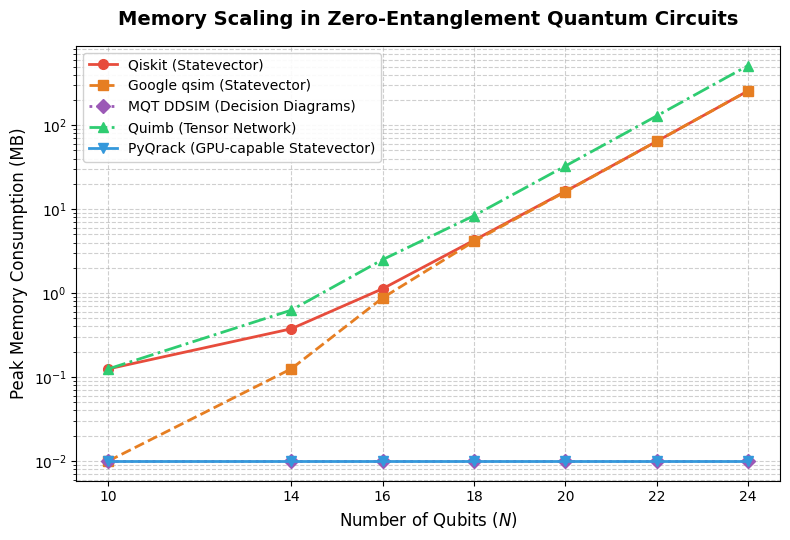

In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# 1. ZERO-ENTANGLEMENT BASELINE DATA
# ==========================================
data = {
    'Qubits': [10, 14, 16, 18, 20, 22, 24],
    
    'Qiskit (Statevector)': 
        [0.125, 0.375, 1.125, 4.250, 16.250, 64.125, 256.250],
        
    'Google qsim (Statevector)': 
        [0.000, 0.125, 0.875, 4.125, 16.086, 64.137, 256.051],
        
    'MQT DDSIM (Decision Diagrams)': 
        [0.000, 0.000, 0.000, 0.000, 0.000, 0.000, 0.000],
        
    'Quimb (Tensor Network)': 
        [0.125, 0.625, 2.500, 8.336, 32.578, 128.820, 512.551],
        
    'PyQrack (GPU-capable Statevector)': 
        [0.000, 0.000, 0.000, 0.000, 0.000, 0.000, 0.000]
}

df = pd.DataFrame(data).set_index('Qubits')

# ==========================================
# 2. PLOT FORMATTING (IEEE Paper Style)
# ==========================================
plt.figure(figsize=(8, 5.5))

# Define colors and markers for distinct, colorblind-friendly lines
styles = {
    'Qiskit (Statevector)': {'color': '#e74c3c', 'marker': 'o', 'linestyle': '-'},
    'Google qsim (Statevector)': {'color': '#e67e22', 'marker': 's', 'linestyle': '--'},
    'Quimb (Tensor Network)': {'color': '#2ecc71', 'marker': '^', 'linestyle': '-.'},
    'MQT DDSIM (Decision Diagrams)': {'color': '#9b59b6', 'marker': 'D', 'linestyle': ':'},
    'PyQrack (GPU-capable Statevector)': {'color': '#3498db', 'marker': 'v', 'linestyle': '-'}
}

# Plot each column
for col in df.columns:
    # Dropna ensures the line stops cleanly if a simulator times out/crashes
    valid_data = df[col].dropna()
    
    # Replace 0.0 with a tiny offset (0.01) so it renders cleanly on the log scale floor
    valid_data = valid_data.replace(0.0, 0.01) 
    
    plt.plot(valid_data.index, valid_data.values, 
             label=col, 
             color=styles[col]['color'], 
             marker=styles[col]['marker'], 
             linestyle=styles[col]['linestyle'], 
             linewidth=2, markersize=7)

# Format the axes
plt.title('Memory Scaling in Zero-Entanglement Quantum Circuits', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Number of Qubits ($N$)', fontsize=12)
plt.ylabel('Peak Memory Consumption (MB)', fontsize=12)

# Use a logarithmic scale for the Y-axis to handle the exponential statevector scaling
plt.yscale('log')
plt.grid(True, which="both", ls="--", alpha=0.6)

# Ensure x-ticks match the qubit counts exactly
plt.xticks(data['Qubits'])

# Add the legend
plt.legend(fontsize=10, loc='upper left', framealpha=0.9)

plt.tight_layout()

# ==========================================
# 3. SAVE THE OUTPUTS
# ==========================================
# Save as PDF for LaTeX (vector graphics scale perfectly without pixelation)
plt.savefig('memory_benchmark_baseline.pdf', format='pdf', dpi=300)
# Save as PNG for quick viewing
plt.savefig('memory_benchmark_baseline.png', format='png', dpi=300)

print("Graph successfully saved as 'memory_benchmark_baseline.pdf' and '.png'")
plt.show()